# CS224N Assignment 1: Exploring Word Vectors (25 Points)
### <font color='blue'> Due 4:30pm, Tue April 9th 2024</font>

Welcome to CS224N! 

Before you start, make sure you **read the README.md** in the same directory as this notebook for important setup information. You need to install some Python libraries before you can successfully do this assignment. A lot of code is provided in this notebook, and we highly encourage you to read and understand it as part of the learning :)

If you aren't super familiar with Python, Numpy, or Matplotlib, we recommend you check out the review session on Friday. The session will be recorded and the material will be made available on our [website](http://web.stanford.edu/class/cs224n/index.html#schedule). The CS231N Python/Numpy [tutorial](https://cs231n.github.io/python-numpy-tutorial/) is also a great resource.


**Assignment Notes:** Please make sure to save the notebook as you go along. Submission Instructions are located at the bottom of the notebook.

# CS224N 作业 1：探索词向量（25 分）
### 截止时间：2024 年 4 月 9 日（周二）下午 4:30

欢迎来到 CS224N！

在开始之前，请务必阅读与本 notebook 同目录下的 **README.md**，其中包含重要的环境配置信息。你需要先安装一些 Python 库，才能顺利完成这份作业。本 notebook 中提供了大量代码，我们强烈建议你在学习过程中阅读并理解它们 :)

如果你对 Python、Numpy 或 Matplotlib 不太熟悉，我们建议你观看周五的复习课。该课程会录像，材料会上传到我们的[网站](http://web.stanford.edu/class/cs224n/index.html#schedule)。CS231N 的 Python/Numpy [教程](https://cs231n.github.io/python-numpy-tutorial/)也是一个很好的资源。

**作业说明：** 请在写作业的过程中随时保存 notebook。提交说明位于 notebook 底部。


In [104]:
# All Import Statements Defined Here（所有 import 语句都在这里定义）
# Note: Do not add to this list.（注意：不要向这个列表中添加内容。）
# ----------------

import sys
assert sys.version_info[0] == 3
assert sys.version_info[1] >= 8

from platform import python_version
assert int(python_version().split(".")[1]) >= 5, "请按照与本 notebook 同目录下的 README.md 文件中的说明升级你的 Python 版本。你当前的 Python 版本是 " + python_version()

from gensim.models import KeyedVectors
from gensim.test.utils import datapath
import pprint
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 5]

from datasets import load_dataset
imdb_dataset = load_dataset("stanfordnlp/imdb")

import re
import numpy as np
import random
import scipy as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA

START_TOKEN = '<START>'
END_TOKEN = '<END>'
NUM_SAMPLES = 150

np.random.seed(0)
random.seed(0)
START_TOKEN
# ----------------

'<START>'

## Word Vectors

Word Vectors are often used as a fundamental component for downstream NLP tasks, e.g. question answering, text generation, translation, etc., so it is important to build some intuitions as to their strengths and weaknesses. Here, you will explore two types of word vectors: those derived from *co-occurrence matrices*, and those derived via *GloVe*. 

**Note on Terminology:** The terms "word vectors" and "word embeddings" are often used interchangeably. The term "embedding" refers to the fact that we are encoding aspects of a word's meaning in a lower dimensional space. As [Wikipedia](https://en.wikipedia.org/wiki/Word_embedding) states, "*conceptually it involves a mathematical embedding from a space with one dimension per word to a continuous vector space with a much lower dimension*".

## 词向量

词向量经常被用作下游 NLP 任务（例如问答、文本生成、翻译等）的基础组件，因此建立对它们优点和缺点的直觉非常重要。在这里，你将探索两种类型的词向量：由*共现矩阵*推导出的词向量，以及通过*GloVe*推导出的词向量。

**术语说明：** “词向量”和“词嵌入”这两个术语经常互换使用。“嵌入”一词指的是我们在一个较低维度的空间中编码一个词含义的各个方面。正如[维基百科](https://en.wikipedia.org/wiki/Word_embedding)所述：“*从概念上讲，它涉及将一个每个词对应一个维度的空间，数学地嵌入到一个维度低得多的连续向量空间中*”。


## Part 1: Count-Based Word Vectors (10 points)

Most word vector models start from the following idea:

*You shall know a word by the company it keeps ([Firth, J. R. 1957:11](https://en.wikipedia.org/wiki/John_Rupert_Firth))*

Many word vector implementations are driven by the idea that similar words, i.e., (near) synonyms, will be used in similar contexts. As a result, similar words will often be spoken or written along with a shared subset of words, i.e., contexts. By examining these contexts, we can try to develop embeddings for our words. With this intuition in mind, many "old school" approaches to constructing word vectors relied on word counts. Here we elaborate upon one of those strategies, *co-occurrence matrices* (for more information, see [here](https://web.stanford.edu/~jurafsky/slp3/6.pdf) or [here](https://web.archive.org/web/20190530091127/https://medium.com/data-science-group-iitr/word-embedding-2d05d270b285)).

## 第一部分：基于计数的词向量（10 分）

大多数词向量模型都源于以下思想：

*你应当通过一个词所搭配的语境来认识这个词（[Firth, J. R. 1957:11](https://en.wikipedia.org/wiki/John_Rupert_Firth)）*

许多词向量的实现都源于这样一个想法：相似的词（即近义词）会出现在相似的语境中。因此，相似的词往往会与一组共同的词（即语境）一起出现。通过考察这些语境，我们可以尝试为我们的词开发出嵌入。基于这种直觉，许多构建词向量的“老派”方法都依赖于词计数。在这里，我们详细阐述其中一种策略——*共现矩阵*（更多信息请参见[这里](https://web.stanford.edu/~jurafsky/slp3/6.pdf)或[这里](https://web.archive.org/web/20190530091127/https://medium.com/data-science-group-iitr/word-embedding-2d05d270b285)）。


### Co-Occurrence

A co-occurrence matrix counts how often things co-occur in some environment. Given some word $w_i$ occurring in the document, we consider the *context window* surrounding $w_i$. Supposing our fixed window size is $n$, then this is the $n$ preceding and $n$ subsequent words in that document, i.e. words $w_{i-n} \dots w_{i-1}$ and $w_{i+1} \dots w_{i+n}$. We build a *co-occurrence matrix* $M$, which is a symmetric word-by-word matrix in which $M_{ij}$ is the number of times $w_j$ appears inside $w_i$'s window among all documents.

**Example: Co-Occurrence with Fixed Window of n=1**:

Document 1: "all that glitters is not gold"

Document 2: "all is well that ends well"


|     *    | `<START>` | all | that | glitters | is   | not  | gold  | well | ends | `<END>` |
|----------|-------|-----|------|----------|------|------|-------|------|------|-----|
| `<START>`    | 0     | 2   | 0    | 0        | 0    | 0    | 0     | 0    | 0    | 0   |
| all      | 2     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| that     | 0     | 1   | 0    | 1        | 0    | 0    | 0     | 1    | 1    | 0   |
| glitters | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| is       | 0     | 1   | 0    | 1        | 0    | 1    | 0     | 1    | 0    | 0   |
| not      | 0     | 0   | 0    | 0        | 1    | 0    | 1     | 0    | 0    | 0   |
| gold     | 0     | 0   | 0    | 0        | 0    | 1    | 0     | 0    | 0    | 1   |
| well     | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 1    | 1   |
| ends     | 0     | 0   | 1    | 0        | 0    | 0    | 0     | 1    | 0    | 0   |
| `<END>`      | 0     | 0   | 0    | 0        | 0    | 0    | 1     | 1    | 0    | 0   |

In NLP, we commonly use `<START>` and `<END>` tokens to mark the beginning and end of sentences, paragraphs, or documents. These tokens are included in co-occurrence counts, encapsulating each document, for example: "`<START>` All that glitters is not gold `<END>`".

The matrix rows (or columns) provide word vectors based on word-word co-occurrence, but they can be large. To reduce dimensionality, we employ Singular Value Decomposition (SVD), akin to PCA, selecting the top $k$ principal components. The SVD process decomposes the co-occurrence matrix $A$ into singular values in the diagonal $S$ matrix and new, shorter word vectors in $U_k$.

This dimensionality reduction maintains semantic relationships; for instance, *doctor* and *hospital* will be closer than *doctor* and *dog*.

For those unfamiliar with eigenvalues and SVD, a beginner-friendly introduction to SVD is available [here](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf). Additional resources for in-depth understanding include lectures [7](https://web.stanford.edu/class/cs168/l/l7.pdf), [8](http://theory.stanford.edu/~tim/s15/l/l8.pdf), and [9](https://web.stanford.edu/class/cs168/l/l9.pdf) of CS168, providing high-level treatment of these algorithms. For practical implementation, utilizing pre-programmed functions from Python packages like numpy, scipy, or sklearn is recommended. While applying full SVD to large corpora can be memory-intensive, scalable techniques such as Truncated SVD exist for extracting the top $k$ vector components efficiently.

### 共现

共现矩阵统计事物在某种环境中共同出现的频率。给定文档中出现的某个词 w_i，我们考虑围绕 w_i 的*上下文窗口*。假设我们固定的窗口大小为 n，那么这就是该文档中 w_i 前面 n 个和后面 n 个词，即 w_{i-n} … w_{i-1} 和 w_{i+1} … w_{i+n} 这些词。我们构建一个*共现矩阵* M，它是一个对称的“词×词”矩阵，其中 M_{ij} 表示在所有文档中 w_j 出现在 w_i 窗口内的次数。

**示例：固定窗口 n=1 的共现**：

文档 1：“all that glitters is not gold”

文档 2：“all is well that ends well”

（对应的共现矩阵表格见上方英文部分）

在 NLP 中，我们通常使用 `<START>` 和 `<END>` 标记来标记句子、段落或文档的开头和结尾。这些标记被计入共现计数，包裹着每个文档，例如：“`<START>` All that glitters is not gold `<END>`”。

矩阵的行（或列）提供了基于词-词共现的词向量，但它们可能非常大。为了降低维度，我们采用奇异值分解（SVD），类似于 PCA，选择前 k 个主成分。SVD 过程将共现矩阵 A 分解为对角矩阵 S 中的奇异值，以及 U_k 中新的、更短的词向量。

这种降维保持了语义关系；例如，*doctor* 和 *hospital* 会比 *doctor* 和 *dog* 更接近。

对于不熟悉特征值和 SVD 的人来说，[这里](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf)有一份适合初学者的 SVD 入门介绍。如需深入理解，可参考 CS168 的讲义 [7](https://web.stanford.edu/class/cs168/l/l7.pdf)、[8](http://theory.stanford.edu/~tim/s15/l/l8.pdf) 和 [9](https://web.stanford.edu/class/cs168/l/l9.pdf)，其中对这些算法做了高层讲解。对于实际实现，推荐使用 numpy、scipy 或 sklearn 等 Python 包中的现成函数。虽然对大型语料库应用完整 SVD 可能非常消耗内存，但存在诸如截断 SVD（Truncated SVD）之类的可扩展技术，可以高效地提取前 k 个向量分量。


### Plotting Co-Occurrence Word Embeddings

Here, we will be using the Large Movie Review Dataset. This is a dataset for binary sentiment classification containing substantially more data than previous benchmark datasets. We provide a set of 25,000 highly polar movie reviews for training, and 25,000 for testing. There is additional unlabeled data for use as well. We provide a `read_corpus` function below that pulls out the text of a movie review from the dataset. The function also adds `<START>` and `<END>` tokens to each of the documents, and lowercases words. You do **not** have to perform any other kind of pre-processing.

### 绘制共现词嵌入

在这里，我们将使用大型电影评论数据集（Large Movie Review Dataset）。这是一个用于二元情感分类的数据集，包含的数据量远多于以往的基准数据集。我们提供了 25,000 条高度两极分化的电影评论用于训练，以及 25,000 条用于测试。此外还有额外的无标签数据可供使用。我们在下面提供了一个 `read_corpus` 函数，用于从数据集中提取电影评论的文本。该函数还会为每个文档添加 `<START>` 和 `<END>` 标记，并将单词转为小写。你**不需要**进行任何其他形式的预处理。


In [105]:
def read_corpus():
    """ Read files from the Large Movie Review Dataset.
        从大型电影评论数据集中读取文件。
        参数：
            category (string)：类别名称
        返回：
            列表的列表，其中包含每个处理后文件中的单词
        Params:
            category (string): category name
        Return:
            list of lists, with words from each of the processed files
    """
    files = imdb_dataset["train"]["text"][:NUM_SAMPLES]
    return [[START_TOKEN] + [re.sub(r'[^\w]', '', w.lower()) for w in f.split(" ")] + [END_TOKEN] for f in files]


Let's have a look what these documents are like….

让我们看看这些文档是什么样的……


In [106]:
imdb_corpus = read_corpus()
pprint.pprint(imdb_corpus[:3], compact=True, width=100)
print("语料库大小：", len(imdb_corpus[0]))

[['<START>', 'i', 'rented', 'i', 'am', 'curiousyellow', 'from', 'my', 'video', 'store', 'because',
  'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first',
  'released', 'in', '1967', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized',
  'by', 'us', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore',
  'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to',
  'see', 'this', 'for', 'myselfbr', 'br', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young',
  'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything',
  'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her',
  'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average',
  'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam',
  'war', 'and', 'race', 'issu

### Question 1.1: Implement `distinct_words` [code] (2 points)

Write a method to work out the distinct words (word types) that occur in the corpus.

You can use `for` loops to process the input `corpus` (a list of list of strings), but try using Python list comprehensions (which are generally faster). In particular, [this](https://coderwall.com/p/rcmaea/flatten-a-list-of-lists-in-one-line-in-python) may be useful to flatten a list of lists. If you're not familiar with Python list comprehensions in general, here's [more information](https://python-3-patterns-idioms-test.readthedocs.io/en/latest/Comprehensions.html).

Your returned `corpus_words` should be sorted. You can use python's `sorted` function for this.

You may find it useful to use [Python sets](https://www.w3schools.com/python/python_sets.asp) to remove duplicate words.

### 问题 1.1：实现 `distinct_words` [代码]（2 分）

编写一个方法，找出语料库中出现的不重复单词（词类型）。

你可以使用 `for` 循环来处理输入的 `corpus`（一个字符串列表的列表），但请尝试使用 Python 列表推导式（通常更快）。特别是，[这里](https://coderwall.com/p/rcmaea/flatten-a-list-of-lists-in-one-line-in-python)的内容可能对展平一个“列表的列表”有帮助。如果你对 Python 列表推导式不太熟悉，[这里](https://python-3-patterns-idioms-test.readthedocs.io/en/latest/Comprehensions.html)有更多信息。

你返回的 `corpus_words` 应该是排好序的。你可以使用 Python 的 `sorted` 函数。

你可能会发现使用 [Python 集合（set）](https://www.w3schools.com/python/python_sets.asp)来去除重复单词很有用。


In [107]:
def distinct_words(corpus):
    """ Determine a list of distinct words for the corpus.
        确定语料库中不重复单词的列表。
        参数：
            corpus（字符串列表的列表）：文档组成的语料库
        返回：
            corpus_words（字符串列表）：整个语料库中不重复单词的排序列表
            n_corpus_words（整数）：整个语料库中不重复单词的数量
        Params:
            corpus (list of list of strings): corpus of documents
        Return:
            corpus_words (list of strings): sorted list of distinct words across the corpus
            n_corpus_words (integer): number of distinct words across the corpus
    """
    corpus_words = sorted(set(word for document in corpus for word in document))
    n_corpus_words = len(corpus_words)
    # ------------------

    return corpus_words, n_corpus_words

In [108]:
# ---------------------
# Run this sanity check（运行这个健全性检查）
# Note that this not an exhaustive check for correctness.（注意：这并非对正确性的穷尽检查。）
# ---------------------

# Define toy corpus（定义示例语料库）
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
test_corpus_words, num_corpus_words = distinct_words(test_corpus)

# Correct answers（正确答案）
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
ans_num_corpus_words = len(ans_test_corpus_words)

# Test correct number of words（测试单词数量是否正确）
assert(num_corpus_words == ans_num_corpus_words), "不同的单词数量不正确。正确值：{}。你的值：{}".format(ans_num_corpus_words, num_corpus_words)

# Test correct words（测试单词是否正确）
assert (test_corpus_words == ans_test_corpus_words), "corpus_words 不正确。\n正确值：{}\n你的值：{}".format(str(ans_test_corpus_words), str(test_corpus_words))

# Print Success（打印成功信息）
print ("-" * 80)
print("已通过所有测试！")
print ("-" * 80)

--------------------------------------------------------------------------------
已通过所有测试！
--------------------------------------------------------------------------------


### Question 1.2: Implement `compute_co_occurrence_matrix` [code] (3 points)

Write a method that constructs a co-occurrence matrix for a certain window-size $n$ (with a default of 4), considering words $n$ before and $n$ after the word in the center of the window. Here, we start to use `numpy (np)` to represent vectors, matrices, and tensors. If you're not familiar with NumPy, there's a NumPy tutorial in the second half of this cs231n [Python NumPy tutorial](http://cs231n.github.io/python-numpy-tutorial/).

### 问题 1.2：实现 `compute_co_occurrence_matrix` [代码]（3 分）

编写一个方法，为某个窗口大小 n（默认为 4）构建共现矩阵，考虑窗口中心词前面 n 个和后面 n 个词。在这里，我们开始使用 `numpy (np)` 来表示向量、矩阵和张量。如果你对 NumPy 不熟悉，这份 cs231n 的 [Python NumPy 教程](http://cs231n.github.io/python-numpy-tutorial/)的后半部分有 NumPy 教程。


In [109]:
def compute_co_occurrence_matrix(corpus, window_size=4):

    words, n_words = distinct_words(corpus)
    #生成索引字典，要用单词当索引，因为这样才能在遍历的时候直接找到
    word2ind = {word: i for i, word in enumerate(words)}
    # 直接生成m矩阵，用0初始化
    M = np.zeros((n_words, n_words))
    # 遍历每篇文档中的每个中心词，统计其窗口内上下文词的出现次数
    for document in corpus:
        for i, center_word in enumerate(document):
            center_idx = word2ind[center_word]
            for j in range(max(0, i - window_size), min(len(document), i + window_size + 1)):
                if j == i:
                    continue
                context_idx = word2ind[document[j]]
                M[center_idx][context_idx] += 1
    # ------------------

    return M, word2ind

In [110]:
# ---------------------
# Run this sanity check（运行这个健全性检查）
# Note that this is not an exhaustive check for correctness.（注意：这并非对正确性的穷尽检查。）
# ---------------------

# Define toy corpus and get student's co-occurrence matrix（定义示例语料库并获取学生的共现矩阵）
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)

# Correct M and word2ind（正确的 M 和 word2ind）
M_test_ans = np.array( 
    [[0., 0., 0., 0., 0., 0., 1., 0., 0., 1.,],
     [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 1., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 0., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 0., 1., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 1., 1., 0.,],
     [1., 0., 0., 0., 0., 0., 0., 1., 0., 0.,],
     [0., 0., 0., 0., 0., 1., 1., 0., 0., 0.,],
     [0., 0., 1., 0., 1., 1., 0., 0., 0., 1.,],
     [1., 0., 0., 1., 1., 0., 0., 0., 1., 0.,]]
)
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
word2ind_ans = dict(zip(ans_test_corpus_words, range(len(ans_test_corpus_words))))

# Test correct word2ind（测试 word2ind 是否正确）
assert (word2ind_ans == word2ind_test), "你的 word2ind 不正确：\n正确值：{}\n你的值：{}".format(word2ind_ans, word2ind_test)

# Test correct M shape（测试 M 的形状是否正确）
assert (M_test.shape == M_test_ans.shape), "M 矩阵的形状不正确。\n正确值：{}\n你的值：{}".format(M_test.shape, M_test_ans.shape)

# Test correct M values（测试 M 的值是否正确）
for w1 in word2ind_ans.keys():
    idx1 = word2ind_ans[w1]
    for w2 in word2ind_ans.keys():
        idx2 = word2ind_ans[w2]
        student = M_test[idx1, idx2]
        correct = M_test_ans[idx1, idx2]
        if student != correct:
            print("正确的 M：")
            print(M_test_ans)
            print("你的 M：")
            print(M_test)
            raise AssertionError("矩阵 M 中索引 ({}, {})=({}, {}) 处的计数不正确。你的值是 {}，但应该是 {}。".format(idx1, idx2, w1, w2, student, correct))

# Print Success（打印成功信息）
print ("-" * 80)
print("已通过所有测试！")
print ("-" * 80)

--------------------------------------------------------------------------------
已通过所有测试！
--------------------------------------------------------------------------------


### Question 1.3: Implement `reduce_to_k_dim` [code] (1 point)

Construct a method that performs dimensionality reduction on the matrix to produce k-dimensional embeddings. Use SVD to take the top k components and produce a new matrix of k-dimensional embeddings. 

**Note:** All of numpy, scipy, and scikit-learn (`sklearn`) provide *some* implementation of SVD, but only scipy and sklearn provide an implementation of Truncated SVD, and only sklearn provides an efficient randomized algorithm for calculating large-scale Truncated SVD. So please use [sklearn.decomposition.TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html).

### 问题 1.3：实现 `reduce_to_k_dim` [代码]（1 分）

编写一个方法，对矩阵进行降维，以产生 k 维嵌入。使用 SVD 取前 k 个分量，产生一个新的 k 维嵌入矩阵。

**注意：** numpy、scipy 和 scikit-learn（`sklearn`）都提供了*某种* SVD 实现，但只有 scipy 和 sklearn 提供截断 SVD 的实现，而且只有 sklearn 提供了用于计算大规模截断 SVD 的高效随机化算法。所以请使用 [sklearn.decomposition.TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html)。


In [111]:
def reduce_to_k_dim(M, k=2):
   #按照这个就可以直接给出答案，但我对此算法不了解，无法解释为什么要这样做
    n_iters = 10    # Use this parameter in your call to `TruncatedSVD`（在调用 `TruncatedSVD` 时使用这个参数）
    M_reduced = None
    print("正在对 %i 个词运行截断 SVD..." % (M.shape[0]))
    
    # ------------------
    # 使用 TruncatedSVD 取前 k 个分量；fit_transform 返回的就是 U * S
    svd = TruncatedSVD(n_components=k, n_iter=n_iters)
    M_reduced = svd.fit_transform(M)
    # ------------------

    print("完成。")
    return M_reduced

In [112]:
# ---------------------
# Run this sanity check（运行这个健全性检查）
# Note that this is not an exhaustive check for correctness（注意：这并非对正确性的穷尽检查） 
# In fact we only check that your M_reduced has the right dimensions.（实际上我们只检查你的 M_reduced 是否具有正确的维度。）
# ---------------------

# Define toy corpus and run student code（定义示例语料库并运行学生代码）
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)
M_test_reduced = reduce_to_k_dim(M_test, k=2)

# Test proper dimensions（测试维度是否正确）
assert (M_test_reduced.shape[0] == 10), "M_reduced 有 {} 行；应该有 {}".format(M_test_reduced.shape[0], 10)
assert (M_test_reduced.shape[1] == 2), "M_reduced 有 {} 列；应该有 {}".format(M_test_reduced.shape[1], 2)

# Print Success（打印成功信息）
print ("-" * 80)
print("已通过所有测试！")
print ("-" * 80)

正在对 10 个词运行截断 SVD...
完成。
--------------------------------------------------------------------------------
已通过所有测试！
--------------------------------------------------------------------------------


### Question 1.4: Implement `plot_embeddings` [code] (1 point)

Here you will write a function to plot a set of 2D vectors in 2D space. For graphs, we will use Matplotlib (`plt`).

For this example, you may find it useful to adapt [this code](http://web.archive.org/web/20190924160434/https://www.pythonmembers.club/2018/05/08/matplotlib-scatter-plot-annotate-set-text-at-label-each-point/). In the future, a good way to make a plot is to look at [the Matplotlib gallery](https://matplotlib.org/gallery/index.html), find a plot that looks somewhat like what you want, and adapt the code they give.

### 问题 1.4：实现 `plot_embeddings` [代码]（1 分）

在这里，你将编写一个函数，在二维空间中绘制一组 2D 向量。对于绘图，我们将使用 Matplotlib（`plt`）。

对于这个例子，你可能会发现改编[这段代码](http://web.archive.org/web/20190924160434/https://www.pythonmembers.club/2018/05/08/matplotlib-scatter-plot-annotate-set-text-at-label-each-point/)很有用。今后，绘图的一个好方法是查看[Matplotlib 图库](https://matplotlib.org/gallery/index.html)，找到一个看起来接近你想要的图，然后改编他们给出的代码。


In [113]:
def plot_embeddings(M_reduced, word2ind, words):
    """ Plot in a scatterplot the embeddings of the words specified in the list "words".
        在散点图中绘制列表 "words" 中指定单词的嵌入。
        注意：不要绘制 M_reduced / word2ind 中列出的所有单词。在每个点旁边加上标签。
        参数：
            M_reduced（形状为（语料库中不重复单词数，2）的 numpy 矩阵）：2 维词嵌入矩阵
            word2ind（字典）：将单词映射到矩阵 M 中索引的字典
            words（字符串列表）：我们想要可视化其嵌入的单词
        NOTE: do not plot all the words listed in M_reduced / word2ind.
        Include a label next to each point.
        
        Params:
            M_reduced (numpy matrix of shape (number of unique words in the corpus , 2)): matrix of 2-dimensioal word embeddings
            word2ind (dict): dictionary that maps word to indices for matrix M
            words (list of strings): words whose embeddings we want to visualize
    """
    for word in words:
        idx = word2ind[word]
        x, y = M_reduced[idx]
        plt.scatter(x, y, marker='x', color='red')
        plt.text(x + 0.0005, y + 0.0005, word, fontsize=9)


--------------------------------------------------------------------------------
输出的图：
--------------------------------------------------------------------------------


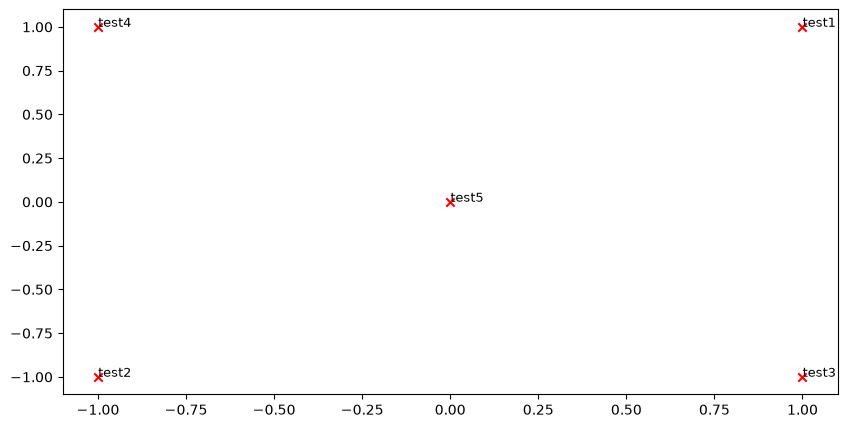

In [114]:
# ---------------------
# Run this sanity check（运行这个健全性检查）
# Note that this is not an exhaustive check for correctness.（注意：这并非对正确性的穷尽检查。）
# The plot produced should look like the included file question_1.4_test.png（生成的图应该与附带文件 question_1.4_test.png 类似） 
# ---------------------

print ("-" * 80)
print ("输出的图：")

M_reduced_plot_test = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1], [0, 0]])
word2ind_plot_test = {'test1': 0, 'test2': 1, 'test3': 2, 'test4': 3, 'test5': 4}
words = ['test1', 'test2', 'test3', 'test4', 'test5']
plot_embeddings(M_reduced_plot_test, word2ind_plot_test, words)

print ("-" * 80)

### Question 1.5: Co-Occurrence Plot Analysis [written] (3 points)

Now we will put together all the parts you have written! We will compute the co-occurrence matrix with fixed window of 4 (the default window size), over the Large Movie Review corpus. Then we will use TruncatedSVD to compute 2-dimensional embeddings of each word. TruncatedSVD returns U\*S, so we need to normalize the returned vectors, so that all the vectors will appear around the unit circle (therefore closeness is directional closeness). **Note**: The line of code below that does the normalizing uses the NumPy concept of *broadcasting*. If you don't know about broadcasting, check out
[Computation on Arrays: Broadcasting by Jake VanderPlas](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html).

Run the below cell to produce the plot. It can take up to a few minutes to run.

### 问题 1.5：共现图分析 [书面]（3 分）

现在，我们将把你写好的所有部分组合起来！我们将在大型电影评论语料库上，使用固定窗口 4（默认窗口大小）计算共现矩阵。然后，我们将使用 TruncatedSVD 计算每个词的 2 维嵌入。TruncatedSVD 返回 U*S，因此我们需要对返回的向量进行归一化，使所有向量都出现在单位圆附近（因此“接近”是方向上的接近）。**注意**：下面做归一化的那行代码使用了 NumPy 的*广播*概念。如果你不了解广播，请参阅
[Computation on Arrays: Broadcasting by Jake VanderPlas](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html)。

运行下面的单元格来生成图。可能需要几分钟才能运行完。


正在对 5880 个词运行截断 SVD...
完成。


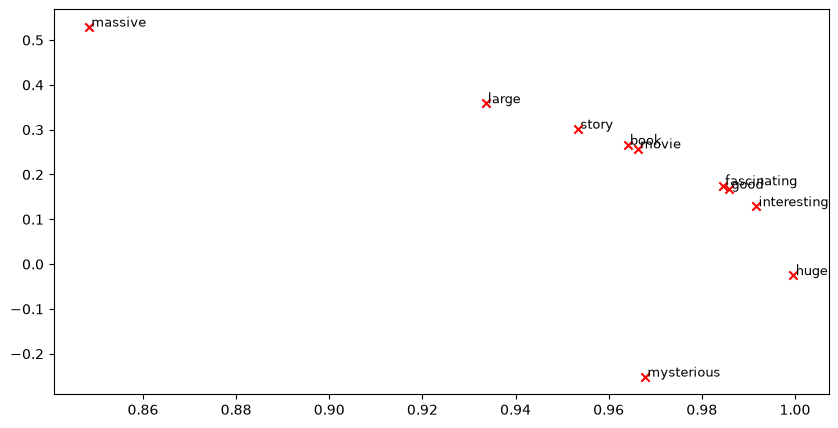

In [115]:
# -----------------------------
# Run This Cell to Produce Your Plot（运行此单元格以生成你的图）
# ------------------------------
imdb_corpus = read_corpus()
M_co_occurrence, word2ind_co_occurrence = compute_co_occurrence_matrix(imdb_corpus)
M_reduced_co_occurrence = reduce_to_k_dim(M_co_occurrence, k=2)

# Rescale (normalize) the rows to make them each of unit-length（重新缩放（归一化）各行，使其成为单位长度）
M_lengths = np.linalg.norm(M_reduced_co_occurrence, axis=1)
M_normalized = M_reduced_co_occurrence / M_lengths[:, np.newaxis] # broadcasting（广播）

words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_normalized, word2ind_co_occurrence, words)

**Verify that your figure matches "question_1.5.png" in the assignment zip. If not, use the figure in "question_1.5.png" to answer the next two questions.**

**请确认你的图与作业压缩包中的 "question_1.5.png" 一致。如果不一致，请使用 "question_1.5.png" 中的图来回答接下来的两个问题。**


a. Find at least two groups of words that cluster together in 2-dimensional embedding space. Give an explanation for each cluster you observe.

a. 在 2 维嵌入空间中找出至少两组聚在一起的词。为你观察到的每一个词簇给出解释。


#### <font color="red">Write your answer here.</font>

在这里写下你的答案。


b. What doesn't cluster together that you might think should have? Describe at least two examples.

b. 有哪些你认为本应聚在一起、但实际上却没有聚在一起的词？请描述至少两个例子。


#### <font color="red">Write your answer here.</font>

在这里写下你的答案。


## Part 2: Prediction-Based Word Vectors (15 points)

As discussed in class, more recently prediction-based word vectors have demonstrated better performance, such as word2vec and GloVe (which also utilizes the benefit of counts). Here, we shall explore the embeddings produced by GloVe. Please revisit the class notes and lecture slides for more details on the word2vec and GloVe algorithms. If you're feeling adventurous, challenge yourself and try reading [GloVe's original paper](https://nlp.stanford.edu/pubs/glove.pdf).

Then run the following cells to load the GloVe vectors into memory. **Note**: If this is your first time to run these cells, i.e. download the embedding model, it will take a couple minutes to run. If you've run these cells before, rerunning them will load the model without redownloading it, which will take about 1 to 2 minutes.

## 第二部分：基于预测的词向量（15 分）

正如课堂上所讨论的，近年来基于预测的词向量表现出了更好的性能，例如 word2vec 和 GloVe（后者还利用了词计数的优势）。在这里，我们将探索由 GloVe 产生的嵌入。请回顾课堂笔记和讲义幻灯片，了解 word2vec 和 GloVe 算法的更多细节。如果你敢于挑战，可以尝试阅读 [GloVe 的原始论文](https://nlp.stanford.edu/pubs/glove.pdf)。

然后运行下面的单元格，将 GloVe 词向量加载到内存中。**注意**：如果这是你第一次运行这些单元格（即下载嵌入模型），运行可能需要几分钟。如果你之前运行过这些单元格，再次运行它们将直接加载模型而无需重新下载，大约需要 1 到 2 分钟。


In [116]:
def load_embedding_model():
    """ Load GloVe Vectors
        加载 GloVe 词向量
        返回：
            wv_from_bin：全部 400000 个嵌入，每个长度为 200
        Return:
            wv_from_bin: All 400000 embeddings, each length 200
    """
    from gensim.models import KeyedVectors
    wv_from_bin = KeyedVectors.load_word2vec_format("glove.6B.200d.bin", binary=True)
    print("已加载的词表大小 %i" % len(list(wv_from_bin.index_to_key)))
    return wv_from_bin
wv_from_bin = load_embedding_model()

已加载的词表大小 400000


#### Note: If you are receiving a "reset by peer" error, rerun the cell to restart the download. 

#### 注意：如果你遇到 "reset by peer" 错误，请重新运行该单元格以重新开始下载。


### Reducing dimensionality of Word Embeddings
Let's directly compare the GloVe embeddings to those of the co-occurrence matrix. In order to avoid running out of memory, we will work with a sample of 40000 GloVe vectors instead.
Run the following cells to:

1. Put 40000 Glove vectors into a matrix M
2. Run `reduce_to_k_dim` (your Truncated SVD function) to reduce the vectors from 200-dimensional to 2-dimensional.

### 降低词嵌入的维度
让我们直接将 GloVe 嵌入与共现矩阵的嵌入进行对比。为了避免内存耗尽，我们将改用 40000 个 GloVe 向量的样本。
运行以下单元格以：

1. 将 40000 个 Glove 向量放入矩阵 M
2. 运行 `reduce_to_k_dim`（你的截断 SVD 函数），将向量从 200 维降到 2 维。


In [117]:
def get_matrix_of_vectors(wv_from_bin, required_words):
    """ Put the GloVe vectors into a matrix M.
        将 GloVe 词向量放入矩阵 M 中。
        参数：
            wv_from_bin：KeyedVectors 对象；从文件中加载的 400000 个 GloVe 词向量
        返回：
            M：形状为 (词数, 200) 的 numpy 矩阵，包含这些向量
            word2ind：将每个单词映射到其在 M 中行号的字典
        Param:
            wv_from_bin: KeyedVectors object; the 400000 GloVe vectors loaded from file
        Return:
            M: numpy matrix shape (num words, 200) containing the vectors
            word2ind: dictionary mapping each word to its row number in M
    """
    import random
    words = list(wv_from_bin.index_to_key)
    print("正在打乱单词顺序 ...")
    random.seed(225)
    random.shuffle(words)
    print("正在将 %i 个单词放入 word2ind 和矩阵 M 中..." % len(words))
    word2ind = {}
    M = []
    curInd = 0
    for w in words:
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    for w in required_words:
        if w in words:
            continue
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    M = np.stack(M)
    print("完成。")
    return M, word2ind

In [118]:
# -----------------------------------------------------------------
# Run Cell to Reduce 200-Dimensional Word Embeddings to k Dimensions（运行此单元格，将 200 维词嵌入降维到 k 维）
# Note: This should be quick to run（注意：这应该运行得很快）
# -----------------------------------------------------------------
M, word2ind = get_matrix_of_vectors(wv_from_bin, words)
M_reduced = reduce_to_k_dim(M, k=2)

# Rescale (normalize) the rows to make them each of unit-length（重新缩放（归一化）各行，使其成为单位长度）
M_lengths = np.linalg.norm(M_reduced, axis=1)
M_reduced_normalized = M_reduced / M_lengths[:, np.newaxis] # broadcasting（广播）

正在打乱单词顺序 ...
正在将 400000 个单词放入 word2ind 和矩阵 M 中...
完成。
正在对 400000 个词运行截断 SVD...
完成。


**Note: If you are receiving out of memory issues on your local machine, try closing other applications to free more memory on your device. You may want to try restarting your machine so that you can free up extra memory. Then immediately run the jupyter notebook and see if you can load the word vectors properly. If you still have problems with loading the embeddings onto your local machine after this, please go to office hours or contact course staff.**

**注意：如果你在本机遇到内存不足的问题，请尝试关闭其他应用程序以释放设备上的内存。你可能需要重启机器以释放额外内存，然后立即运行 jupyter notebook，看看能否正确加载词向量。如果在此之后你仍然无法在本机加载嵌入，请前往答疑时间或联系课程助教。**


### Question 2.1: GloVe Plot Analysis [written] (3 points)

Run the cell below to plot the 2D GloVe embeddings for `['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']`.

### 问题 2.1：GloVe 图分析 [书面]（3 分）

运行下面的单元格，为 `['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']` 绘制 2D GloVe 嵌入图。


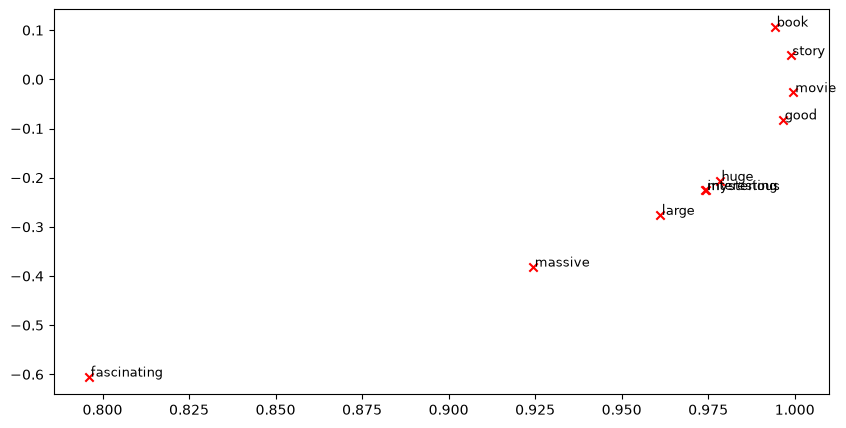

In [119]:
words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_reduced_normalized, word2ind, words)

**Verify that your figure matches "question_2.1.png" in the assignment zip. If not, use the figure in "question_2.1.png" (and the figure in "question_1.5.png", if applicable) to answer the next two questions.**

**请确认你的图与作业压缩包中的 "question_2.1.png" 一致。如果不一致，请使用 "question_2.1.png" 中的图（以及 "question_1.5.png" 中的图，如果适用）来回答接下来的两个问题。**


a. What is one way the plot is different from the one generated earlier from the co-occurrence matrix? What is one way it's similar?

a. 这张图与之前由共现矩阵生成的图有什么不同之处？有什么相似之处？


#### <font color="red">Write your answer here.</font>

在这里写下你的答案。


b. Why might the GloVe plot (question_2.1.png) differ from the plot generated earlier from the co-occurrence matrix (question_1.5.png)?

b. 为什么 GloVe 图（question_2.1.png）可能与之前由共现矩阵生成的图（question_1.5.png）不同？


#### <font color="red">Write your answer here.</font>

不一样是肯定的，因为一个是完全基于频率统计出来的，而glove更多考虑了语义

### Cosine Similarity
Now that we have word vectors, we need a way to quantify the similarity between individual words, according to these vectors. One such metric is cosine-similarity. We will be using this to find words that are "close" and "far" from one another.

We can think of n-dimensional vectors as points in n-dimensional space. If we take this perspective [L1](http://mathworld.wolfram.com/L1-Norm.html) and [L2](http://mathworld.wolfram.com/L2-Norm.html) Distances help quantify the amount of space "we must travel" to get between these two points. Another approach is to examine the angle between two vectors. From trigonometry we know that:

<img src="./imgs/inner_product.png" width=20% style="float: center;"></img>

Instead of computing the actual angle, we can leave the similarity in terms of $similarity = cos(\Theta)$. Formally the [Cosine Similarity](https://en.wikipedia.org/wiki/Cosine_similarity) $s$ between two vectors $p$ and $q$ is defined as:

$$s = \frac{p \cdot q}{||p|| ||q||}, \textrm{ where } s \in [-1, 1] $$

### 余弦相似度
现在我们有了词向量，我们需要一种方法来根据这些向量量化单个词之间的相似度。其中一种度量是余弦相似度。我们将用它来找出彼此“相近”和“相远”的词。

我们可以把 n 维向量看作 n 维空间中的点。从这个角度看，[L1](http://mathworld.wolfram.com/L1-Norm.html) 和 [L2](http://mathworld.wolfram.com/L2-Norm.html) 距离有助于量化我们在两点之间“需要走过的空间量”。另一种方法是考察两个向量之间的夹角。由三角学可知：

<img src="./imgs/inner_product.png" width=20% style="float: center;"></img>

与其计算实际角度，我们可以把相似度表示为 $similarity = cos(\Theta)$。形式上，两个向量 $p$ 和 $q$ 之间的[余弦相似度](https://en.wikipedia.org/wiki/Cosine_similarity) $s$ 定义为：

$$s = \frac{p \cdot q}{||p|| ||q||}, \textrm{ where } s \in [-1, 1] $$


### Question 2.2: Words with Multiple Meanings (1.5 points) [code + written] 
Polysemes and homonyms are words that have more than one meaning (see this [wiki page](https://en.wikipedia.org/wiki/Polysemy) to learn more about the difference between polysemes and homonyms ). Find a word with *at least two different meanings* such that the top-10 most similar words (according to cosine similarity) contain related words from *both* meanings. For example, "leaves" has both "go_away" and "a_structure_of_a_plant" meaning in the top 10, and "scoop" has both "handed_waffle_cone" and "lowdown". You will probably need to try several polysemous or homonymic words before you find one. 

Please state the word you discover and the multiple meanings that occur in the top 10. Why do you think many of the polysemous or homonymic words you tried didn't work (i.e. the top-10 most similar words only contain **one** of the meanings of the words)?

**Note**: You should use the `wv_from_bin.most_similar(word)` function to get the top 10 most similar words. This function ranks all other words in the vocabulary with respect to their cosine similarity to the given word. For further assistance, please check the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.most_similar)__.

### 问题 2.2：具有多重含义的词（1.5 分）[代码 + 书面]
多义词（polysemes）和同形异义词（homonyms）是具有不止一个含义的词（参见这个[维基页面](https://en.wikipedia.org/wiki/Polysemy)了解多义词和同形异义词之间的区别）。找到一个具有*至少两个不同含义*的词，使得其 top-10 最相似的词（根据余弦相似度）同时包含来自*这两个*含义的相关词。例如，"leaves" 在 top 10 中既有 "go_away"（离开）也有 "a_structure_of_a_plant"（植物的结构）的含义；"scoop" 既有 "handed_waffle_cone"（手工华夫筒）也有 "lowdown"（内幕消息）。你可能需要尝试好几个多义词或同形异义词才能找到一个。

请说明你发现的词，以及出现在 top 10 中的多重含义。你认为为什么你尝试的许多多义词或同形异义词不奏效（即 top-10 最相似的词只包含该词的**其中一个**含义）？

**注意**：你应该使用 `wv_from_bin.most_similar(word)` 函数来获取 top 10 最相似的词。该函数根据与给定词的余弦相似度对词汇表中所有其他词进行排序。如需进一步帮助，请查阅 __[GenSim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.most_similar)__。


In [120]:
# ------------------
# Write your implementation here.（在这里编写你的实现。）

wv_from_bin.most_similar(positive=['leaves'], topn=10)

# ------------------

[('ends', 0.6128067970275879),
 ('leaf', 0.6027014851570129),
 ('stems', 0.5998532176017761),
 ('takes', 0.5902854800224304),
 ('leaving', 0.5761634111404419),
 ('grows', 0.5663396716117859),
 ('flowers', 0.5600922107696533),
 ('turns', 0.5536050796508789),
 ('leave', 0.5496848821640015),
 ('goes', 0.5434925556182861)]

#### <font color="red">Write your answer here.</font>

多个词义出现的时候，也会有使用频率的差异，因此会找不到同义词


### Question 2.3: Synonyms & Antonyms (2 points) [code + written] 

When considering Cosine Similarity, it's often more convenient to think of Cosine Distance, which is simply 1 - Cosine Similarity.

Find three words $(w_1,w_2,w_3)$ where $w_1$ and $w_2$ are synonyms and $w_1$ and $w_3$ are antonyms, but Cosine Distance $(w_1,w_3) <$ Cosine Distance $(w_1,w_2)$. 

As an example, $w_1$="happy" is closer to $w_3$="sad" than to $w_2$="cheerful". Please find a different example that satisfies the above. Once you have found your example, please give a possible explanation for why this counter-intuitive result may have happened.

You should use the the `wv_from_bin.distance(w1, w2)` function here in order to compute the cosine distance between two words. Please see the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.distance)__ for further assistance.

### 问题 2.3：同义词与反义词（2 分）[代码 + 书面]

在考虑余弦相似度时，通常更方便考虑余弦距离（Cosine Distance），它其实就是 1 - 余弦相似度。

找出三个词 (w1, w2, w3)，其中 w1 和 w2 是同义词，w1 和 w3 是反义词，但余弦距离 (w1, w3) < 余弦距离 (w1, w2)。

作为一个例子，w1="happy" 比 w2="cheerful" 更接近 w3="sad"。请找出一个满足上述条件的不同的例子。找到你的例子后，请给出一个可能的解释，说明为什么会发生这种反直觉的结果。

这里你应该使用 `wv_from_bin.distance(w1, w2)` 函数来计算两个词之间的余弦距离。如需进一步帮助，请参见 __[GenSim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.distance)__。


In [121]:
print(wv_from_bin.distance("hot","warm"))
print(wv_from_bin.distance("hot","cold"))

0.41116732
0.4062189


#### <font color="red">Write your answer here.</font>

GloVe 词向量学习单词经常和哪些词一起出现  ，并没有把语义考虑的很好


### Question 2.4: Analogies with Word Vectors [written] (1.5 points)
Word vectors have been shown to *sometimes* exhibit the ability to solve analogies. 

As an example, for the analogy "man : grandfather :: woman : x" (read: man is to grandfather as woman is to x), what is x?

In the cell below, we show you how to use word vectors to find x using the `most_similar` function from the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.most_similar)__. The function finds words that are most similar to the words in the `positive` list and most dissimilar from the words in the `negative` list (while omitting the input words, which are often the most similar; see [this paper](https://www.aclweb.org/anthology/N18-2039.pdf)). The answer to the analogy will have the highest cosine similarity (largest returned numerical value).

### 问题 2.4：用词向量做类比 [书面]（1.5 分）
研究表明，词向量*有时*能表现出解决类比的能力。

例如，对于类比 "man : grandfather :: woman : x"（读作：man 之于 grandfather 如同 woman 之于 x），x 是什么？

在下面的单元格中，我们向你展示如何使用 __[GenSim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.most_similar)__ 中的 `most_similar` 函数，用词向量来找到 x。该函数会找到与 `positive` 列表中的词最相似、同时与 `negative` 列表中的词最不相似的词（同时省略输入词，因为输入词通常是最相似的；参见[这篇论文](https://www.aclweb.org/anthology/N18-2039.pdf)）。类比的答案将具有最高的余弦相似度（返回的数值最大）。


In [122]:
# For example: x, y, a, b = ("", "", "", "")
# ------------------
# Write your implementation here.（在这里编写你的实现。）
x, y, a, b = ("king", "man", "queen", "woman")

# ------------------

# Test the solution（测试这个解）
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] == b

#### <font color="red">Write your answer here.</font>

x, y, a, b = ("king", "man", "queen", "woman")


### Question 2.6: Incorrect Analogy [code + written] (1.5 points)
a. Below, we expect to see the intended analogy "hand : glove :: foot : **sock**", but we see an unexpected result instead. Give a potential reason as to why this particular analogy turned out the way it did?

### 问题 2.6：不正确的类比 [代码 + 书面]（1.5 分）
a. 下面，我们期望看到预期的类比 "hand : glove :: foot : **sock**"，但我们却看到了一个意外的结果。请给出一个潜在的原因，说明为什么这个特定的类比会出现这样的结果？


In [123]:
pprint.pprint(wv_from_bin.most_similar(positive=['foot', 'glove'], negative=['hand']))

[('45,000-square', 0.4922032058238983),
 ('15,000-square', 0.4649604558944702),
 ('10,000-square', 0.45447564125061035),
 ('6,000-square', 0.44975772500038147),
 ('3,500-square', 0.4441334009170532),
 ('700-square', 0.44257503747940063),
 ('50,000-square', 0.4356396794319153),
 ('3,000-square', 0.43486514687538147),
 ('30,000-square', 0.4330596923828125),
 ('footed', 0.43236875534057617)]


#### <font color="red">Write your answer here.</font>

在这里写下你的答案。
找到了很多其他词汇，不是sock，我觉得是hand和glove之间的距离 与foot和sock的不一样，这与训练数据有关，数据就是不对称的，虽然考虑的语义，但是也无法修正


b. Find another example of analogy that does *not* hold according to these vectors. In your solution, state the intended analogy in the form x:y :: a:b, and state the **incorrect** value of b according to the word vectors (in the previous example, this would be **'45,000-square'**).

b. 找出另一个根据这些向量*不*成立的类比例子。在你的解答中，以 x:y :: a:b 的形式说明预期的类比，并说明根据词向量得出的 b 的**错误**值（在前面的例子中，这个值就是 **'45,000-square'**）。


In [124]:
# For example: x, y, a, b = ("", "", "", "")（例如：x, y, a, b = ("", "", "", "")）
# ------------------
# Write your implementation here.（在这里编写你的实现。）
x, y, a, b = ("pen", "write", "knife", "cut")
# ------------------
pprint.pprint(wv_from_bin.most_similar(positive=[a, y], negative=[x]))
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] != b

[('you', 0.48027661442756653),
 ('how', 0.45332497358322144),
 ("'d", 0.4527038335800171),
 ('cover', 0.4514838457107544),
 ('tell', 0.44960734248161316),
 ('whatever', 0.4456719756126404),
 ('piece', 0.44481360912323),
 ("'ll", 0.43800321221351624),
 ('done', 0.430388480424881),
 ('writing', 0.4287570118904114)]


#### <font color="red">Write your answer here.</font>

应该是cut，因为 这个pen 对应刀  所以写，对应cut，蛋这里写的是you




### Question 2.7: Guided Analysis of Bias in Word Vectors [written] (1 point)

It's important to be cognizant of the biases (gender, race, sexual orientation etc.) implicit in our word embeddings. Bias can be dangerous because it can reinforce stereotypes through applications that employ these models.

Run the cell below, to examine (a) which terms are most similar to "man" and "profession" and most dissimilar to "woman" and (b) which terms are most similar to "woman" and "profession" and most dissimilar to "man". Point out the difference between the list of female-associated words and the list of male-associated words, and explain how it is reflecting gender bias.

### 问题 2.7：词向量中偏见的引导分析 [书面]（1 分）

意识到我们的词嵌入中隐含的偏见（性别、种族、性取向等）非常重要。偏见可能是危险的，因为它可能通过使用这些模型的应用来强化刻板印象。

运行下面的单元格，考察 (a) 哪些词与 "man" 和 "profession" 最相似、同时与 "woman" 最不相似，以及 (b) 哪些词与 "woman" 和 "profession" 最相似、同时与 "man" 最不相似。指出女性关联词列表与男性关联词列表之间的差异，并解释它如何反映性别偏见。


In [126]:
pprint.pprint(wv_from_bin.most_similar(positive=['man', 'profession'], negative=['woman']))
print()
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'profession'], negative=['man']))

[('reputation', 0.5250176787376404),
 ('professions', 0.5178037881851196),
 ('skill', 0.49046966433525085),
 ('skills', 0.49005505442619324),
 ('ethic', 0.4897659420967102),
 ('business', 0.487585186958313),
 ('respected', 0.4859202802181244),
 ('practice', 0.482104629278183),
 ('regarded', 0.4778572916984558),
 ('life', 0.4760662019252777)]

[('professions', 0.5957458019256592),
 ('practitioner', 0.4988412857055664),
 ('teaching', 0.48292139172554016),
 ('nursing', 0.48211804032325745),
 ('vocation', 0.4788965880870819),
 ('teacher', 0.47160348296165466),
 ('practicing', 0.46937811374664307),
 ('educator', 0.46524327993392944),
 ('physicians', 0.4628995656967163),
 ('professionals', 0.4601394236087799)]


#### <font color="red">Write your answer here.</font>
男性偏商务，声望，专业，技能  女性偏生活，教师，护士教育护理等等，也就是说，这个向量空间因为训练数据的原因，已经产生了偏见，导致模型在用这个词库的时候，会产生bias



### Question 2.8: Independent Analysis of Bias in Word Vectors [code + written]  (1 point)

Use the `most_similar` function to find another pair of analogies that demonstrates some bias is exhibited by the vectors. Please briefly explain the example of bias that you discover.

### 问题 2.8：词向量中偏见的独立分析 [代码 + 书面]（1 分）

使用 `most_similar` 函数找出另一对能证明这些向量表现出某种偏见的类比。请简要解释你发现的这个偏见示例。


In [ ]:
# ------------------
# Write your implementation here.（在这里编写你的实现。）
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'doctor'], negative=['man']))
#man ：doctor ：：woman ：nurse
# ------------------

[('nurse', 0.6813318729400635),
 ('physician', 0.6672453880310059),
 ('doctors', 0.6173422932624817),
 ('dentist', 0.5775880217552185),
 ('surgeon', 0.5691418647766113),
 ('hospital', 0.564996600151062),
 ('pregnant', 0.5649074912071228),
 ('nurses', 0.5590692162513733),
 ('medical', 0.5542058944702148),
 ('patient', 0.5518485307693481)]


#### <font color="red">Write your answer here.</font>
man ：doctor ：：woman ：nurse他认为女性在就应该对应护士，2️而不是doctor


### Question 2.9: Thinking About Bias [written] (2 points)

a. Give one explanation of how bias gets into the word vectors. Briefly describe a real-world example that demonstrates this source of bias. Your real-world example should be focused on word vectors, as opposed to bias in other AI systems (e.g., ChatGPT).

### 问题 2.9：关于偏见的思考 [书面]（2 分）

a. 给出一种解释，说明偏见是如何进入词向量的。简要描述一个展示这种偏见来源的现实世界例子。你的现实世界例子应聚焦于词向量，而不是其他 AI 系统（例如 ChatGPT）中的偏见。


#### <font color="red">Write your answer here.</font>

我感觉，偏见的来源是训练的copora，内容大多来自我们的现实生活，生活中，提到男人，大多认为他干的都是些比较有技术含量的活，提到学生，大多会提到，男生学理，女生学文。。。
这些导致训练数据的偏见，进而导致词库偏见


b. What is one method you can use to mitigate bias exhibited by word vectors? Briefly describe a real-world example that demonstrates this method.

b. 你可以使用什么方法来缓解词向量表现出的偏见？简要描述一个展示这种方法的现实世界例子。



#### <font color="red">Write your answer here.</font>

在这里写下你的答案。


# <font color="blue"> Submission Instructions</font>

1. Click the Save button at the top of the Jupyter Notebook.
2. Select Cell -> All Output -> Clear. This will clear all the outputs from all cells (but will keep the content of all cells). 
2. Select Cell -> Run All. This will run all the cells in order, and will take several minutes.
3. Once you've rerun everything, select File -> Download as -> PDF via LaTeX (If you have trouble using "PDF via LaTex", you can also save the webpage as pdf. <font color='blue'> Make sure all your solutions especially the coding parts are displayed in the pdf</font>, it's okay if the provided codes get cut off because lines are not wrapped in code cells).
4. Look at the PDF file and make sure all your solutions are there, displayed correctly. The PDF is the only thing your graders will see!
5. Submit your PDF on Gradescope.

# <font color="blue"> 提交说明</font>

1. 点击 Jupyter Notebook 顶部的保存按钮。
2. 选择 Cell -> All Output -> Clear。这将清除所有单元格的所有输出（但会保留所有单元格的内容）。
2. 选择 Cell -> Run All。这将按顺序运行所有单元格，需要几分钟。
3. 全部重新运行后，选择 File -> Download as -> PDF via LaTeX（如果你在使用 "PDF via LaTex" 时遇到问题，也可以将网页另存为 PDF。<font color='blue'> 请确保你所有的解答，尤其是代码部分，都显示在 PDF 中</font>；如果提供的代码因为代码单元格中的行不换行而被截断，那也没关系）。
4. 查看 PDF 文件，确保你所有的解答都在里面，并且显示正确。PDF 是评分者唯一会看到的东西！
5. 在 Gradescope 上提交你的 PDF。
